# Classificação de Tumores Mamários com Aprendizado de Máquina

## 1. Introdução

Este projeto tem como objetivo aplicar técnicas de aprendizado de máquina para classificar tumores mamários como benignos ou malignos, utilizando o conjunto de dados *Breast Cancer Wisconsin (Diagnostic)*, disponibilizado na plataforma Kaggle.

O problema é um exemplo de classificação supervisionada, pois os dados possuem diagnósticos conhecidos que serão utilizados para treinar e avaliar os modelos.

Ao longo do projeto, serão realizadas a exploração e a preparação dos dados, a visualização de características relevantes, o treinamento de modelos de classificação e a comparação de seus desempenhos por meio de métricas apropriadas.

O objetivo é compreender como essas técnicas podem identificar padrões nos dados e avaliar suas limitações em um problema real.

**Observação:** este projeto possui finalidade exclusivamente acadêmica e não deve ser utilizado para realizar diagnósticos médicos.

## 2. Descrição do conjunto de dados

O conjunto de dados *Breast Cancer Wisconsin (Diagnostic)* contém informações sobre amostras de tumores mamários, classificadas como benignas ou malignas. Os dados incluem características numéricas calculadas a partir de imagens digitalizadas de amostras, relacionadas à forma, ao tamanho e a outros aspectos dos núcleos celulares.

A base utilizada possui 569 amostras e 30 características numéricas que podem ser utilizadas como variáveis de entrada para os modelos de classificação. A variável `diagnosis` representa o diagnóstico conhecido de cada amostra, sendo `B` correspondente a benigno e `M` correspondente a maligno.

Na distribuição original, 357 amostras são benignas e 212 são malignas. Essa distribuição será considerada durante a preparação dos dados e a avaliação dos modelos.

**Fonte:** [Breast Cancer Wisconsin (Diagnostic) — Kaggle](https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data).

In [2]:
# Importa a biblioteca pandas, utilizada para carregar e analisar tabelas.
import pandas as pd

# Importa a biblioteca matplotlib, utilizada para criar gráficos.
import matplotlib.pyplot as plt

# Importa a biblioteca seaborn, que facilita a criação de visualizações estatísticas.
import seaborn as sns

# Define o endereço público do arquivo CSV com os dados.
url = "https://raw.githubusercontent.com/kairess/breast_cancer_prediction/master/data.csv"

# Lê o arquivo CSV e armazena os dados em um DataFrame.
# Um DataFrame é uma estrutura tabular semelhante a uma planilha.
df = pd.read_csv(url)

# Exibe as cinco primeiras linhas para conferir se os dados foram carregados.
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [3]:
# Exibe a quantidade de linhas e colunas do dataset.
print("Dimensões do dataset:", df.shape)

# Exibe os nomes de todas as colunas.
print("\nColunas disponíveis:")
print(df.columns.tolist())

# Exibe os tipos de dados e a quantidade de valores não nulos.
print("\nInformações gerais:")
df.info()

Dimensões do dataset: (569, 33)

Colunas disponíveis:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']

Informações gerais:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean        

### 2.1. Verificação de valores ausentes

Nesta etapa, verificaremos se existem valores ausentes nas colunas do dataset. Essa análise é importante porque alguns algoritmos de aprendizado de máquina não aceitam dados ausentes diretamente, podendo exigir a remoção ou o preenchimento desses valores.

Também identificaremos colunas que não possuem informações úteis para a análise e que poderão ser removidas durante a preparação dos dados.

In [4]:
# Conta quantos valores ausentes existem em cada coluna.
valores_ausentes = df.isnull().sum()

# Exibe somente as colunas que possuem pelo menos um valor ausente.
print("Colunas com valores ausentes:")
print(valores_ausentes[valores_ausentes > 0])

Colunas com valores ausentes:
Unnamed: 32    569
dtype: int64


### 2.2. Distribuição da variável-alvo

A variável `diagnosis` representa o diagnóstico associado a cada amostra. Ela será utilizada como variável-alvo no treinamento dos modelos.

Analisar sua distribuição permite verificar quantas amostras pertencem a cada classe e identificar se existe um desequilíbrio entre os diagnósticos. Essa informação é importante para interpretar corretamente as métricas de avaliação dos modelos.

Quantidade por diagnóstico:
diagnosis
B    357
M    212
Name: count, dtype: int64

Porcentagem por diagnóstico:
diagnosis
B    62.74
M    37.26
Name: proportion, dtype: float64


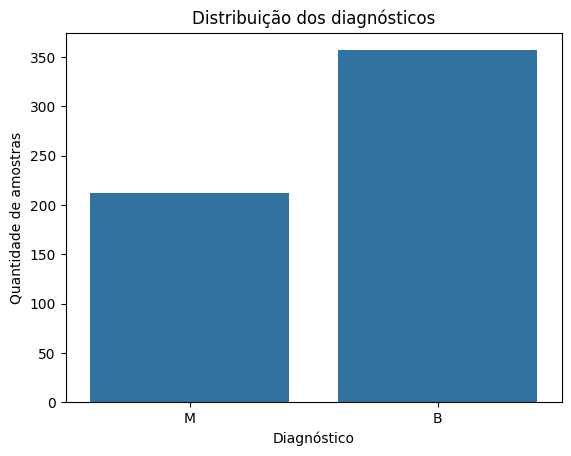

In [5]:
# Conta a quantidade de amostras de cada diagnóstico.
contagem_diagnosticos = df["diagnosis"].value_counts()

# Exibe a quantidade de amostras de cada classe.
print("Quantidade por diagnóstico:")
print(contagem_diagnosticos)

# Calcula a porcentagem de cada classe em relação ao total.
print("\nPorcentagem por diagnóstico:")
print((df["diagnosis"].value_counts(normalize=True) * 100).round(2))

# Cria um gráfico de barras para visualizar a distribuição das classes.
sns.countplot(data=df, x="diagnosis")

# Define o título e os nomes dos eixos.
plt.title("Distribuição dos diagnósticos")
plt.xlabel("Diagnóstico")
plt.ylabel("Quantidade de amostras")

# Exibe o gráfico.
plt.show()

### 2.3. Estatísticas descritivas

Utilizaremos estatísticas descritivas para observar a distribuição das características numéricas, incluindo média, desvio-padrão, valores mínimos e máximos e quartis.

Essa análise ajuda a identificar diferenças de escala entre as variáveis e possíveis valores extremos. Essas informações serão úteis para decidir quais etapas de preparação serão necessárias antes do treinamento dos modelos.

In [6]:
# Seleciona somente as colunas numéricas do dataset.
dados_numericos = df.select_dtypes(include="number")

# Calcula estatísticas descritivas das variáveis numéricas.
estatisticas = dados_numericos.describe()

# Exibe a tabela de estatísticas.
estatisticas

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


### 3. Preparação inicial dos dados

Nesta etapa, removeremos as colunas que não contribuem diretamente para a tarefa de classificação.

A coluna `id` funciona apenas como identificador de cada amostra e não representa uma característica biológica do tumor. Já a coluna `Unnamed: 32` não contém nenhum valor preenchido.

A remoção dessas colunas simplifica o conjunto de dados e evita que informações irrelevantes sejam utilizadas no treinamento dos modelos. A variável `diagnosis` será mantida, pois representa a resposta que queremos prever.

In [7]:
# Cria uma cópia do dataset original para preservar os dados carregados.
df_limpo = df.copy()

# Remove a coluna de identificação e a coluna completamente vazia.
df_limpo = df_limpo.drop(columns=["id", "Unnamed: 32"])

# Exibe as dimensões após a remoção das colunas.
print("Dimensões após a limpeza:", df_limpo.shape)

# Mostra as primeiras linhas do dataset atualizado.
df_limpo.head()

Dimensões após a limpeza: (569, 31)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### 3.1. Distribuição das características numéricas

Utilizaremos histogramas para observar a distribuição de algumas características dos tumores. Esse tipo de gráfico permite identificar concentrações de valores, assimetrias e possíveis observações extremas.

A análise inicial dessas distribuições também ajuda a compreender por que pode ser necessário padronizar as variáveis antes de utilizar determinados algoritmos.

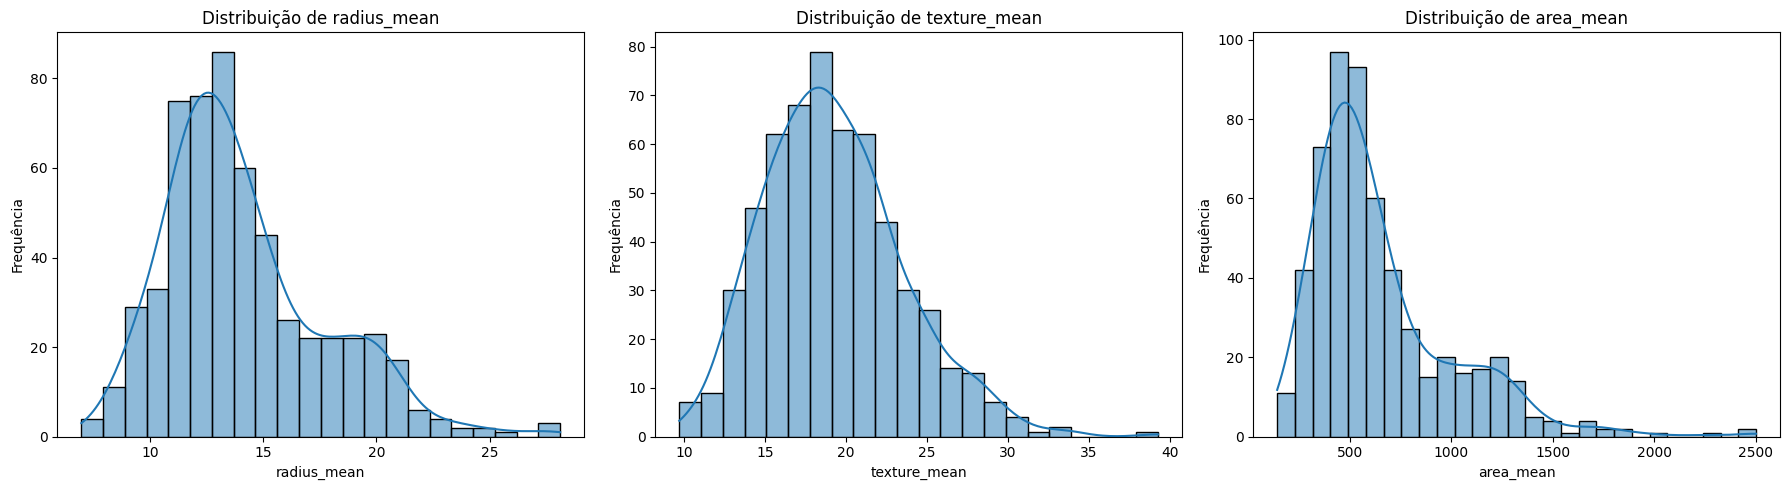

In [8]:
# Define as características que serão analisadas.
caracteristicas = ["radius_mean", "texture_mean", "area_mean"]

# Cria uma figura com três gráficos lado a lado.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Percorre cada característica e o eixo correspondente.
for coluna, ax in zip(caracteristicas, axes):

    # Cria um histograma para visualizar a distribuição dos valores.
    sns.histplot(data=df_limpo, x=coluna, kde=True, ax=ax)

    # Define o título e os rótulos do gráfico.
    ax.set_title(f"Distribuição de {coluna}")
    ax.set_xlabel(coluna)
    ax.set_ylabel("Frequência")

# Ajusta o espaçamento entre os gráficos.
plt.tight_layout()

# Exibe a figura.
plt.show()

### 3.2. Comparação das características por diagnóstico

Nesta análise, compararemos as características numéricas entre as duas classes de diagnóstico.

Os boxplots mostram a mediana, a dispersão dos valores e possíveis observações extremas. Eles ajudam a identificar características que podem apresentar padrões diferentes entre tumores benignos e malignos.

Essas diferenças podem ser úteis para a classificação, mas não significam, isoladamente, que uma característica seja suficiente para determinar o diagnóstico.

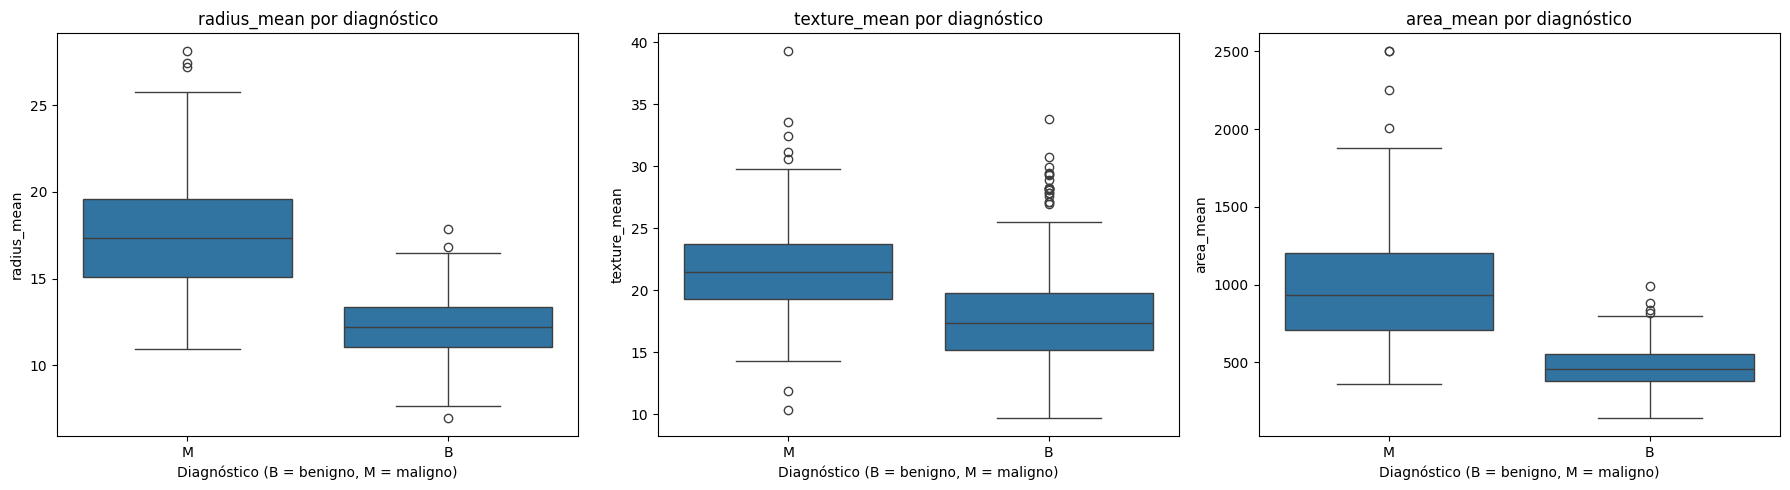

In [9]:
# Define as características que serão comparadas.
caracteristicas = ["radius_mean", "texture_mean", "area_mean"]

# Cria três gráficos de comparação.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Percorre cada característica para gerar um boxplot.
for coluna, ax in zip(caracteristicas, axes):

    # Compara a distribuição da característica entre os diagnósticos.
    sns.boxplot(data=df_limpo, x="diagnosis", y=coluna, ax=ax)

    # Define o título e os rótulos.
    ax.set_title(f"{coluna} por diagnóstico")
    ax.set_xlabel("Diagnóstico (B = benigno, M = maligno)")
    ax.set_ylabel(coluna)

# Organiza os gráficos para evitar sobreposição.
plt.tight_layout()

# Exibe os resultados.
plt.show()

### 4. Definição das variáveis de entrada e da variável-alvo

Para aplicar o aprendizado supervisionado, precisamos separar as características utilizadas para realizar as previsões da informação que desejamos prever.

Neste projeto, a variável `X` conterá as 30 características numéricas dos tumores, enquanto a variável `y` conterá os diagnósticos, classificados como benignos (`B`) ou malignos (`M`).

Essa separação permite que os modelos aprendam relações entre as características dos tumores e os diagnósticos conhecidos.

In [10]:
# Separa as características numéricas que serão utilizadas nas previsões.
X = df_limpo.drop(columns=["diagnosis"])

# Define a coluna de diagnóstico como a variável que queremos prever.
y = df_limpo["diagnosis"]

# Confere as dimensões das variáveis.
print("Dimensões de X:", X.shape)
print("Dimensões de y:", y.shape)

# Exibe uma amostra das características e dos diagnósticos.
display(X.head())
display(y.head())

Dimensões de X: (569, 30)
Dimensões de y: (569,)


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


,diagnosis
0,M
1,M
2,M
3,M
4,M


### 4.1. Divisão dos dados em treinamento e teste

Os dados serão divididos em dois conjuntos: treinamento e teste. Utilizaremos 80% das amostras para treinar os modelos e reservaremos 20% para a avaliação final.

O parâmetro `random_state=42` garante que a divisão possa ser reproduzida em execuções futuras. Já o parâmetro `stratify=y` mantém aproximadamente a mesma proporção de diagnósticos benignos e malignos nos dois conjuntos.

O conjunto de teste será reservado para a avaliação final, evitando utilizá-lo durante o treinamento e a seleção dos modelos.

In [11]:
# Importa a função responsável por dividir os dados.
from sklearn.model_selection import train_test_split

# Divide as características e os diagnósticos em treinamento e teste.
X_train, X_test, y_train, y_test = train_test_split(
    X,                  # Características de entrada.
    y,                  # Diagnósticos que queremos prever.
    test_size=0.20,     # Reserva 20% dos dados para o teste.
    random_state=42,    # Permite reproduzir a mesma divisão.
    stratify=y          # Preserva a proporção das classes.
)

# Exibe a quantidade de amostras em cada conjunto.
print("Amostras para treinamento:", X_train.shape[0])
print("Amostras para teste:", X_test.shape[0])

# Confere a distribuição dos diagnósticos nos dois conjuntos.
print("\nDistribuição no treinamento:")
print(y_train.value_counts(normalize=True).round(3))

print("\nDistribuição no teste:")
print(y_test.value_counts(normalize=True).round(3))

Amostras para treinamento: 455
Amostras para teste: 114

Distribuição no treinamento:
diagnosis
B    0.626
M    0.374
Name: proportion, dtype: float64

Distribuição no teste:
diagnosis
B    0.632
M    0.368
Name: proportion, dtype: float64


### 5. Primeiro modelo: Regressão Logística

A Regressão Logística será utilizada como primeiro modelo de classificação. Ela estima a probabilidade de uma amostra pertencer a determinada classe a partir das características de entrada.

Como as variáveis apresentam escalas diferentes, utilizaremos o `StandardScaler` para padronizá-las. As etapas serão organizadas em um `Pipeline`, garantindo que o ajuste da padronização ocorra somente com os dados usados no treinamento de cada divisão.

Essa organização também facilita a aplicação da validação cruzada e reduz o risco de vazamento de informações entre os conjuntos de treinamento e avaliação.

In [12]:
# Importa o recurso que organiza várias etapas em uma única sequência.
from sklearn.pipeline import Pipeline

# Importa a técnica de padronização das características.
from sklearn.preprocessing import StandardScaler

# Importa o algoritmo de Regressão Logística.
from sklearn.linear_model import LogisticRegression

# Cria um pipeline com duas etapas:
# 1. Padronizar as características.
# 2. Treinar o classificador.
modelo_logistico = Pipeline([
    ("padronizacao", StandardScaler()),
    ("classificador", LogisticRegression(max_iter=1000, random_state=42))
])

# Treina o pipeline usando apenas os dados de treinamento.
modelo_logistico.fit(X_train, y_train)

# Realiza previsões para as amostras do conjunto de teste.
y_pred_logistico = modelo_logistico.predict(X_test)

# Exibe algumas previsões e compara com os diagnósticos reais.
print("Diagnósticos previstos:")
print(y_pred_logistico[:10])

print("\nDiagnósticos reais:")
print(y_test.iloc[:10].to_numpy())

Diagnósticos previstos:
['B' 'M' 'B' 'M' 'M' 'B' 'M' 'B' 'B' 'B']

Diagnósticos reais:
['B' 'M' 'B' 'M' 'B' 'B' 'M' 'B' 'B' 'B']


### 5.1. Avaliação da Regressão Logística

Utilizaremos diferentes métricas para avaliar o modelo, pois a acurácia isoladamente não mostra todos os tipos de erro que podem ocorrer.

- **Acurácia:** proporção total de previsões corretas.
- **Precisão:** entre as amostras previstas como malignas, quantas realmente são malignas.
- **Recall:** entre as amostras realmente malignas, quantas foram identificadas corretamente.
- **F1-score:** média harmônica entre precisão e recall, permitindo avaliar o equilíbrio entre essas duas métricas.

Para precisão, recall e F1-score, consideraremos a classe maligna (`M`) como a classe positiva, por ser importante identificar os casos malignos. Essas métricas serão interpretadas no contexto acadêmico do projeto, sem finalidade de diagnóstico médico.

In [13]:
# Importa as métricas utilizadas para avaliar o classificador.
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calcula a acurácia: proporção de previsões corretas.
acuracia = accuracy_score(y_test, y_pred_logistico)

# Calcula a precisão considerando M (maligno) como classe positiva.
precisao = precision_score(
    y_test, y_pred_logistico,
    pos_label="M"
)

# Calcula o recall para a classe M.
recall = recall_score(
    y_test, y_pred_logistico,
    pos_label="M"
)

# Calcula o F1-score para a classe M.
f1 = f1_score(
    y_test, y_pred_logistico,
    pos_label="M"
)

# Exibe as métricas com quatro casas decimais.
print(f"Acurácia:  {acuracia:.4f}")
print(f"Precisão:  {precisao:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

# Apresenta um relatório detalhado para as duas classes.
print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred_logistico))

Acurácia:  0.9649
Precisão:  0.9750
Recall:    0.9286
F1-score:  0.9512

Relatório de classificação:
              precision    recall  f1-score   support

           B       0.96      0.99      0.97        72
           M       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



### 5.2. Interpretação dos resultados da Regressão Logística

A Regressão Logística alcançou acurácia de aproximadamente 96,49% no conjunto de teste. Para a classe maligna, apresentou precisão de 97,50%, recall de 92,86% e F1-score de 95,12%.

Os resultados indicam que o modelo apresentou bom desempenho na classificação das amostras avaliadas. Entretanto, o recall de 92,86% mostra que algumas amostras malignas não foram identificadas corretamente. Por isso, é importante analisar a matriz de confusão e comparar o modelo com outras técnicas antes de chegar a uma conclusão.

Como a avaliação foi realizada em apenas uma divisão dos dados, os resultados também serão complementados por validação cruzada.

### 5.3. Matriz de confusão

A matriz de confusão permite comparar os diagnósticos reais com os previstos pelo modelo. Ela ajuda a identificar os verdadeiros positivos, verdadeiros negativos, falsos positivos e falsos negativos.

Neste projeto, um falso negativo ocorre quando uma amostra maligna é classificada como benigna. Um falso positivo ocorre quando uma amostra benigna é classificada como maligna.

Essa análise complementa as métricas numéricas e permite compreender melhor os tipos de erro cometidos pelo classificador.

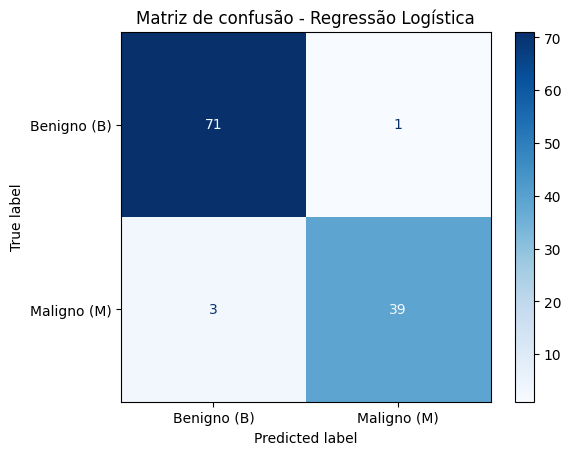

In [14]:
# Importa as ferramentas para calcular e visualizar a matriz de confusão.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Define a ordem das classes para facilitar a interpretação do gráfico.
classes = ["B", "M"]

# Compara os diagnósticos reais com as previsões do modelo.
matriz = confusion_matrix(
    y_test,
    y_pred_logistico,
    labels=classes
)

# Cria o gráfico da matriz de confusão.
visualizacao = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Benigno (B)", "Maligno (M)"]
)

# Exibe a matriz com os valores em cada célula.
visualizacao.plot(cmap="Blues", values_format="d")

# Define o título do gráfico.
plt.title("Matriz de confusão - Regressão Logística")

# Exibe o resultado.
plt.show()

### 5.4. Modelo Random Forest

O Random Forest é um algoritmo de aprendizado supervisionado que combina várias árvores de decisão para realizar classificações. Cada árvore produz uma previsão, e o modelo combina os resultados para definir a classificação final.

Esse algoritmo foi escolhido para comparação com a Regressão Logística, pois consegue representar relações não lineares entre as características e o diagnóstico. A comparação permite verificar se um modelo baseado em várias árvores apresenta resultados melhores para o conjunto de dados utilizado.

In [15]:
# Importa o classificador Random Forest.
from sklearn.ensemble import RandomForestClassifier

# Cria o modelo com parâmetros definidos para permitir
# a reprodução dos resultados.
modelo_random_forest = RandomForestClassifier(
    n_estimators=200,  # Quantidade de árvores da floresta.
    random_state=42,   # Mantém os resultados reproduzíveis.
    class_weight="balanced"  # Considera a proporção entre as classes.
)

# Treina o modelo usando somente os dados de treinamento.
modelo_random_forest.fit(X_train, y_train)

# Realiza as previsões para o conjunto de teste.
y_pred_random_forest = modelo_random_forest.predict(X_test)

print("Primeiras 10 previsões do Random Forest:")
print(y_pred_random_forest[:10])

print("\nPrimeiros 10 diagnósticos reais:")
print(y_test.iloc[:10].to_numpy())

Primeiras 10 previsões do Random Forest:
['B' 'M' 'B' 'M' 'B' 'B' 'M' 'B' 'B' 'B']

Primeiros 10 diagnósticos reais:
['B' 'M' 'B' 'M' 'B' 'B' 'M' 'B' 'B' 'B']


In [16]:
# Calcula as métricas do Random Forest no conjunto de teste.
acuracia_rf = accuracy_score(y_test, y_pred_random_forest)

# Considera a classe M (maligno) como a classe positiva.
precisao_rf = precision_score(
    y_test, y_pred_random_forest, pos_label="M"
)

recall_rf = recall_score(
    y_test, y_pred_random_forest, pos_label="M"
)

f1_rf = f1_score(
    y_test, y_pred_random_forest, pos_label="M"
)

# Exibe as métricas com quatro casas decimais.
print(f"Acurácia:  {acuracia_rf:.4f}")
print(f"Precisão:  {precisao_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print(f"F1-score:  {f1_rf:.4f}")

# Apresenta as métricas detalhadas para as duas classes.
print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred_random_forest))

Acurácia:  0.9649
Precisão:  1.0000
Recall:    0.9048
F1-score:  0.9500

Relatório de classificação:
              precision    recall  f1-score   support

           B       0.95      1.00      0.97        72
           M       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



### 6. Validação cruzada

A validação cruzada foi utilizada para avaliar a estabilidade dos modelos e reduzir a dependência de uma única divisão dos dados. Foi adotada a estratégia *Stratified K-Fold* com cinco divisões, que procura preservar a proporção entre as classes em cada parte.

Foram utilizadas as métricas acurácia, recall e F1-score, com atenção especial à classe maligna. O recall permite observar a proporção de amostras malignas identificadas corretamente, enquanto o F1-score combina precisão e recall.

A validação cruzada será aplicada somente ao conjunto de treinamento. O conjunto de teste permanecerá reservado para a avaliação final dos modelos.

In [17]:
# Importa as ferramentas para validação cruzada.
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Define cinco divisões, mantendo a proporção das classes.
validacao_cruzada = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Recria a Regressão Logística como um pipeline.
# A padronização acontece dentro de cada divisão,
# evitando vazamento de informações entre treino e validação.
modelo_logistico_cv = Pipeline([
    ("padronizacao", StandardScaler()),
    ("classificador", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Define as métricas que serão calculadas em cada rodada.
metricas = {
    "acuracia": "accuracy",
    "recall": "recall_macro",
    "f1": "f1_macro"
}

# Avalia a Regressão Logística somente nos dados de treinamento.
resultados_logistico_cv = cross_validate(
    modelo_logistico_cv,
    X_train,
    y_train,
    cv=validacao_cruzada,
    scoring=metricas
)

# Avalia o Random Forest nas mesmas divisões.
resultados_rf_cv = cross_validate(
    modelo_random_forest,
    X_train,
    y_train,
    cv=validacao_cruzada,
    scoring=metricas
)

# Organiza as médias e os desvios-padrão dos resultados.
import pandas as pd

resumo_cv = pd.DataFrame({
    "Modelo": ["Regressão Logística", "Random Forest"],
    "Acurácia média": [
        resultados_logistico_cv["test_acuracia"].mean(),
        resultados_rf_cv["test_acuracia"].mean()
    ],
    "Recall macro médio": [
        resultados_logistico_cv["test_recall"].mean(),
        resultados_rf_cv["test_recall"].mean()
    ],
    "F1-score macro médio": [
        resultados_logistico_cv["test_f1"].mean(),
        resultados_rf_cv["test_f1"].mean()
    ],
    "Desvio-padrão da acurácia": [
        resultados_logistico_cv["test_acuracia"].std(),
        resultados_rf_cv["test_acuracia"].std()
    ]
})

# Exibe os resultados arredondados para facilitar a leitura.
display(resumo_cv.round(4))

,Modelo,Acurácia média,Recall macro médio,F1-score macro médio,Desvio-padrão da acurácia
0,Regressão Logística,0.9736,0.9695,0.9716,0.0149
1,Random Forest,0.9626,0.9583,0.9599,0.0132


### 6.1. Interpretação da validação cruzada

A validação cruzada foi realizada utilizando cinco divisões dos dados de treinamento. A Regressão Logística apresentou acurácia média de 97,36%, recall macro médio de 96,95% e F1-score macro médio de 97,16%. O Random Forest obteve acurácia média de 96,26%, recall macro médio de 95,83% e F1-score macro médio de 95,99%.

Os resultados indicam que a Regressão Logística apresentou melhor desempenho médio nas métricas avaliadas. O Random Forest apresentou um desvio-padrão da acurácia ligeiramente menor, indicando menor variação entre as divisões utilizadas na validação cruzada.

Com base nesses resultados, a Regressão Logística demonstrou ser uma alternativa promissora para este conjunto de dados. Entretanto, a escolha do modelo também deve considerar os resultados obtidos no conjunto de teste e os tipos de erro cometidos, especialmente a identificação incorreta de amostras malignas.

## 7. Comparação dos modelos

Nesta etapa, os resultados da Regressão Logística e do Random Forest são organizados para permitir uma comparação entre as técnicas utilizadas.

A avaliação considera as métricas obtidas no conjunto de teste e as médias calculadas pela validação cruzada. No conjunto de teste, são analisadas a acurácia, a precisão, o recall e o F1-score da classe maligna. Na validação cruzada, são consideradas a acurácia média, o recall macro médio, o F1-score macro médio e o desvio-padrão da acurácia.

Essa comparação permite analisar tanto o desempenho dos modelos nas amostras reservadas para teste quanto a consistência dos resultados em diferentes divisões dos dados de treinamento.

In [18]:
# Organiza os resultados dos dois modelos em uma única tabela.
comparacao_modelos = pd.DataFrame({
    "Modelo": [
        "Regressão Logística",
        "Random Forest"
    ],

    # Resultados obtidos no conjunto de teste.
    "Acurácia teste": [
        acuracia,
        acuracia_rf
    ],
    "Precisão M teste": [
        precisao,
        precisao_rf
    ],
    "Recall M teste": [
        recall,
        recall_rf
    ],
    "F1-score M teste": [
        f1,
        f1_rf
    ],

    # Resultados médios da validação cruzada.
    "Acurácia média CV": [
        resultados_logistico_cv["test_acuracia"].mean(),
        resultados_rf_cv["test_acuracia"].mean()
    ],
    "Recall macro CV": [
        resultados_logistico_cv["test_recall"].mean(),
        resultados_rf_cv["test_recall"].mean()
    ],
    "F1-score macro CV": [
        resultados_logistico_cv["test_f1"].mean(),
        resultados_rf_cv["test_f1"].mean()
    ],
    "Desvio-padrão CV": [
        resultados_logistico_cv["test_acuracia"].std(),
        resultados_rf_cv["test_acuracia"].std()
    ]
})

# Formata os valores para facilitar a leitura.
display(
    comparacao_modelos.style.format({
        coluna: "{:.4f}"
        for coluna in comparacao_modelos.columns
        if coluna != "Modelo"
    })
)

,Modelo,Acurácia teste,Precisão M teste,Recall M teste,F1-score M teste,Acurácia média CV,Recall macro CV,F1-score macro CV,Desvio-padrão CV
0,Regressão Logística,0.9649,0.9750,0.9286,0.9512,0.9736,0.9695,0.9716,0.0149
1,Random Forest,0.9649,1.0000,0.9048,0.9500,0.9626,0.9583,0.9599,0.0132


### 7.1. Interpretação da comparação dos modelos

A comparação dos resultados mostrou que os dois modelos alcançaram acurácia de 96,49% no conjunto de teste. Entretanto, a Regressão Logística apresentou recall de 92,86% e F1-score de 95,12% para a classe maligna, enquanto o Random Forest obteve recall de 90,48% e F1-score de 95,00%.

O Random Forest apresentou precisão de 100% para a classe maligna no conjunto de teste, indicando que todas as amostras classificadas como malignas nessa avaliação pertenciam realmente a essa classe. Por outro lado, seu recall foi menor, o que significa que uma quantidade maior de amostras malignas não foi identificada corretamente.

Na validação cruzada, a Regressão Logística também apresentou melhores resultados médios de acurácia, recall macro e F1-score macro. O Random Forest apresentou um desvio-padrão da acurácia ligeiramente menor.

Considerando o conjunto de resultados, a Regressão Logística se destacou pelo desempenho médio e pelo recall da classe maligna. Ainda assim, essa comparação se limita ao conjunto de dados e às configurações utilizadas neste experimento.

## 8. Análise da curva ROC

A curva ROC (*Receiver Operating Characteristic*) permite avaliar a capacidade de um classificador de distinguir as duas classes em diferentes limiares de decisão. Neste trabalho, a classe maligna será considerada positiva.

A área sob a curva ROC (AUC) resume o desempenho de discriminação do modelo. Valores mais próximos de 1 indicam maior capacidade de distinguir as classes, enquanto valores próximos de 0,5 indicam desempenho semelhante ao de uma classificação aleatória.

A curva ROC será utilizada como uma métrica complementar, junto aos resultados de acurácia, precisão, recall e F1-score.

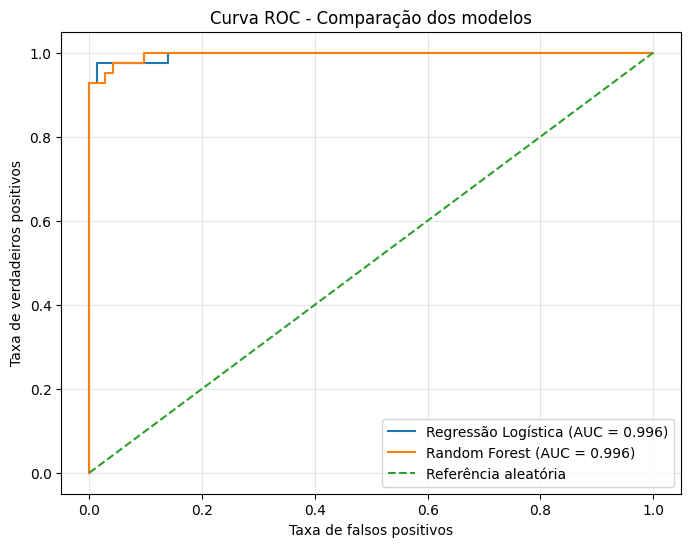

AUC - Regressão Logística: 0.9960
AUC - Random Forest:       0.9960


In [19]:
# Importa as ferramentas para calcular e desenhar a curva ROC.
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Obtém a probabilidade prevista de cada amostra pertencer
# à classe maligna (M), para cada modelo.
# No pipeline, predict_proba mantém a ordem das classes
# em modelo_logistico.classes_.
indice_m_logistico = list(modelo_logistico.classes_).index("M")
probabilidades_logistico = modelo_logistico.predict_proba(X_test)[
    :, indice_m_logistico
]

# No Random Forest, identificamos a posição da classe M.
indice_m_rf = list(modelo_random_forest.classes_).index("M")
probabilidades_rf = modelo_random_forest.predict_proba(X_test)[
    :, indice_m_rf
]

# Calcula os pontos das curvas ROC.
fpr_logistico, tpr_logistico, _ = roc_curve(
    y_test, probabilidades_logistico, pos_label="M"
)
fpr_rf, tpr_rf, _ = roc_curve(
    y_test, probabilidades_rf, pos_label="M"
)

# Calcula a área sob a curva ROC (AUC).
auc_logistico = roc_auc_score(
    (y_test == "M").astype(int), probabilidades_logistico
)
auc_rf = roc_auc_score(
    (y_test == "M").astype(int), probabilidades_rf
)

# Desenha as duas curvas para facilitar a comparação.
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_logistico, tpr_logistico,
    label=f"Regressão Logística (AUC = {auc_logistico:.3f})"
)
plt.plot(
    fpr_rf, tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.3f})"
)

# A diagonal representa uma referência de classificação aleatória.
plt.plot([0, 1], [0, 1], linestyle="--", label="Referência aleatória")

plt.xlabel("Taxa de falsos positivos")
plt.ylabel("Taxa de verdadeiros positivos")
plt.title("Curva ROC - Comparação dos modelos")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Exibe os valores de AUC.
print(f"AUC - Regressão Logística: {auc_logistico:.4f}")
print(f"AUC - Random Forest:       {auc_rf:.4f}")

### 8.1. Interpretação da curva ROC

A análise da curva ROC mostrou que a Regressão Logística e o Random Forest obtiveram AUC de 0,9960. Esse resultado indica que ambos os modelos apresentaram excelente capacidade de discriminação entre as classes benigna e maligna no conjunto de teste.

As duas curvas ficaram próximas ao canto superior esquerdo do gráfico, região associada a uma alta taxa de verdadeiros positivos e uma baixa taxa de falsos positivos. Além disso, ambas ficaram distantes da diagonal de referência, que representa um desempenho equivalente ao de uma classificação aleatória.

Apesar do mesmo valor de AUC, os modelos apresentaram diferenças em outras métricas, como precisão e recall para a classe maligna. Portanto, a curva ROC deve ser interpretada em conjunto com as demais métricas, e não como único critério para selecionar o modelo.

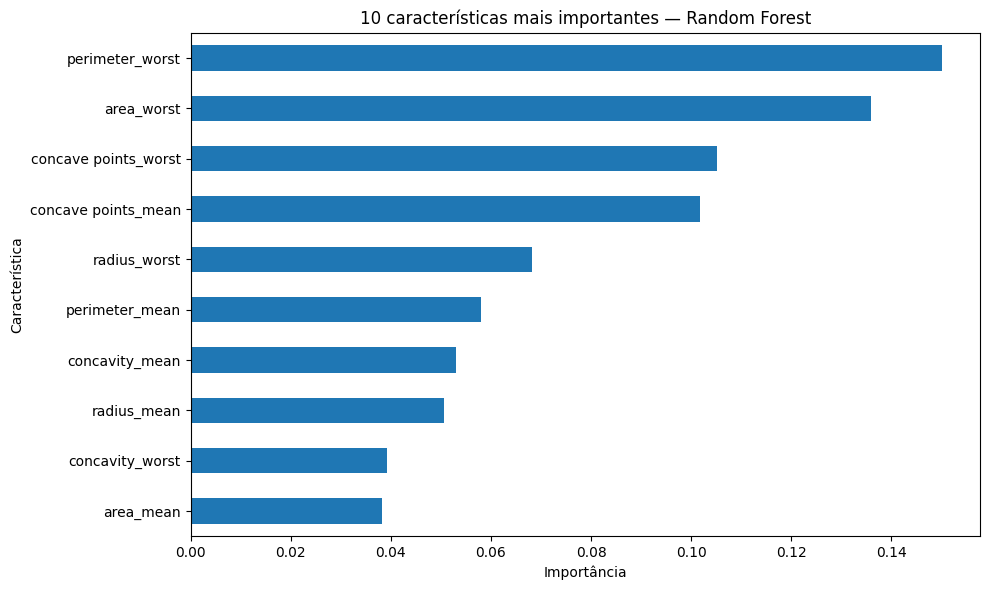

In [20]:

# Identifica a importância de cada característica no Random Forest
importancias = pd.Series(
    modelo_random_forest.feature_importances_,
    index=X_train.columns
)

# Seleciona as 10 características com maior importância
top_10 = importancias.sort_values(ascending=False).head(10)

# Cria um gráfico de barras horizontais
plt.figure(figsize=(10, 6))
top_10.sort_values().plot(kind="barh")

plt.title("10 características mais importantes — Random Forest")
plt.xlabel("Importância")
plt.ylabel("Característica")
plt.tight_layout()
plt.show()


### Importância das características

Para compreender quais variáveis tiveram maior influência nas previsões do Random Forest, analisamos a importância das características calculada pelo próprio modelo.

O gráfico mostra que `perimeter_worst` e `area_worst` apresentaram os maiores valores de importância, seguidas por `concave points_worst` e `concave points_mean`. Esse resultado indica que as medidas relacionadas ao perímetro, à área e ao contorno das células contribuíram de forma relevante para as decisões do classificador.

A análise permite compreender melhor como o modelo utiliza as informações disponíveis para realizar a classificação. Entretanto, a importância atribuída pelo Random Forest não representa causalidade e não significa que uma única característica seja suficiente para determinar se um tumor é benigno ou maligno. Além disso, características correlacionadas podem compartilhar ou influenciar a distribuição da importância.

## 9. Conclusão

Este trabalho teve como objetivo desenvolver e avaliar modelos de aprendizado de máquina para classificar tumores de mama como benignos ou malignos, utilizando o conjunto de dados Breast Cancer Wisconsin (Diagnostic). Foram analisadas 569 amostras, com 30 características numéricas utilizadas como variáveis de entrada para os classificadores.

Inicialmente, foi realizada uma análise exploratória para compreender a distribuição das classes, verificar valores ausentes e observar características relevantes dos dados. Em seguida, foram removidas as colunas desnecessárias para a classificação e os dados foram divididos em conjuntos de treinamento e teste, preservando a proporção entre as classes.

Foram implementados dois modelos: Regressão Logística e Random Forest. No conjunto de teste, ambos alcançaram acurácia de 96,49%. Para a classe maligna, a Regressão Logística obteve precisão de 97,50%, recall de 92,86% e F1-score de 95,12%. O Random Forest apresentou precisão de 100%, recall de 90,48% e F1-score de 95,00%.

Na validação cruzada com cinco divisões, a Regressão Logística apresentou acurácia média de 97,36%, recall macro médio de 96,95% e F1-score macro médio de 97,16%. O Random Forest obteve, respectivamente, 96,26%, 95,83% e 95,99%. Além disso, os dois modelos alcançaram AUC de 0,9960 no conjunto de teste, indicando excelente capacidade de discriminação entre as classes avaliadas.

Considerando o conjunto de resultados, a Regressão Logística apresentou o melhor desempenho médio na validação cruzada e um recall ligeiramente superior para a classe maligna no teste. Dessa forma, mostrou-se a alternativa mais promissora entre os modelos avaliados neste experimento.

### 9.1. Limitações do trabalho

Apesar dos resultados obtidos, o experimento apresenta limitações. A análise foi realizada em um único conjunto de dados, com uma divisão específica entre treinamento e teste. A validação cruzada contribui para avaliar a estabilidade dos modelos, mas não garante que os mesmos resultados serão obtidos em outros conjuntos de dados.

Além disso, foram avaliados apenas dois algoritmos e não foi realizada uma validação externa com dados independentes de outra origem. Os resultados dependem das características do conjunto utilizado e das configurações escolhidas para os modelos.

Por fim, este projeto possui finalidade acadêmica e educacional. Os resultados não devem ser utilizados para diagnóstico médico, substituição da avaliação de profissionais de saúde ou tomada de decisões clínicas.